## Experiment 05: Regularized Linear Models (Ridge, Lasso & ElasticNet)
## Title: Ridge and Lasso Regularization - Influence on Overfitting and Multicollinearity

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** California Housing Dataset (`sklearn.datasets.fetch_california_housing`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load and Prepare California Housing Dataset
We take a sample of 1,000 instances to demonstrate regularization shrinkage and sparsity dynamics.

In [2]:
housing = fetch_california_housing(as_frame=True)
df_housing = housing.frame.sample(n=1000, random_state=42).reset_index(drop=True)

X = df_housing.drop(columns=['MedHouseVal'])
y = df_housing['MedHouseVal']

print(f"Sample shape: {X.shape}")
print("Predictor features:", list(X.columns))

Sample shape: (1000, 8)
Predictor features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


### Step 3: Induce Multicollinearity via Polynomial Interactions

In [3]:
# Create degree-2 interactions to induce severe multicollinearity
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)
feature_names = poly.get_feature_names_out(X.columns)

print(f"Expanded Multicollinear Features: {X_poly.shape[1]}")

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.3, random_state=42)

# Standardize feature matrix
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Expanded Multicollinear Features: 44


### Step 4: Fit OLS vs Ridge (L2) vs Lasso (L1) vs ElasticNet

In [4]:
# 1. Unregularized OLS
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

# 2. Ridge (L2 Penalty)
ridge = Ridge(alpha=50.0)
ridge.fit(X_train_scaled, y_train)

# 3. Lasso (L1 Penalty)
lasso = Lasso(alpha=0.03, max_iter=2000)
lasso.fit(X_train_scaled, y_train)

# 4. ElasticNet (L1 + L2 Combo)
elastic = ElasticNet(alpha=0.03, l1_ratio=0.5, max_iter=2000)
elastic.fit(X_train_scaled, y_train)

print("Models trained successfully.")

Models trained successfully.


### Step 5: Visualizing Coefficient Shrinkage and Feature Sparsity

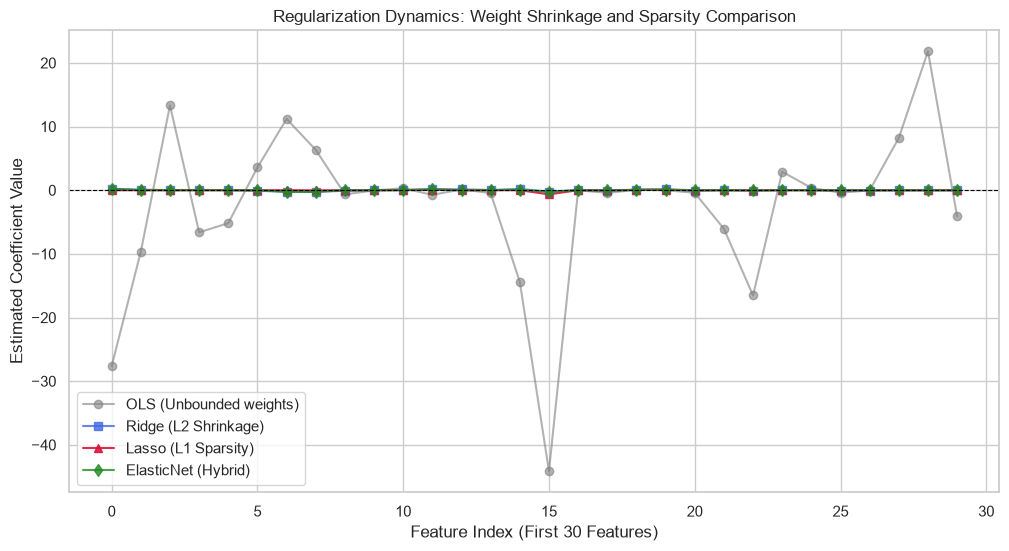

Total Features                  : 44
OLS Non-Zero Coefficients       : 44
Ridge Non-Zero Coefficients     : 44
Lasso Non-Zero Coefficients     : 9 (Sparse selection)
ElasticNet Non-Zero Coefficients: 17


In [5]:
plt.figure(figsize=(12, 6))
plt.plot(ols.coef_[:30], 'o-', label='OLS (Unbounded weights)', alpha=0.6, color='gray')
plt.plot(ridge.coef_[:30], 's-', label='Ridge (L2 Shrinkage)', alpha=0.8, color='royalblue')
plt.plot(lasso.coef_[:30], '^-', label='Lasso (L1 Sparsity)', alpha=0.9, color='crimson')
plt.plot(elastic.coef_[:30], 'd-', label='ElasticNet (Hybrid)', alpha=0.8, color='forestgreen')

plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel("Feature Index (First 30 Features)")
plt.ylabel("Estimated Coefficient Value")
plt.title("Regularization Dynamics: Weight Shrinkage and Sparsity Comparison")
plt.legend()
plt.show()

# Count active (non-zero) weights
print(f"Total Features                  : {X_poly.shape[1]}")
print(f"OLS Non-Zero Coefficients       : {np.sum(ols.coef_ != 0)}")
print(f"Ridge Non-Zero Coefficients     : {np.sum(ridge.coef_ != 0)}")
print(f"Lasso Non-Zero Coefficients     : {np.sum(np.abs(lasso.coef_) > 1e-4)} (Sparse selection)")
print(f"ElasticNet Non-Zero Coefficients: {np.sum(np.abs(elastic.coef_) > 1e-4)}")

### Step 6: Automated Hyperparameter Tuning via Cross-Validation

In [6]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

alphas = np.logspace(-2, 2, 40)

ridge_cv = RidgeCV(alphas=alphas, cv=5).fit(X_train_scaled, y_train)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000, tol=1e-3, random_state=42).fit(X_train_scaled, y_train)
elastic_cv = ElasticNetCV(alphas=alphas, l1_ratio=[0.2, 0.5, 0.8], cv=5, max_iter=10000, tol=1e-3, random_state=42).fit(X_train_scaled, y_train)

print(f"Optimal Ridge alpha      : {ridge_cv.alpha_:.4f}")
print(f"Optimal Lasso alpha      : {lasso_cv.alpha_:.4f}")
print(f"Optimal ElasticNet alpha : {elastic_cv.alpha_:.4f} (l1_ratio={elastic_cv.l1_ratio_})")

Optimal Ridge alpha      : 19.1448
Optimal Lasso alpha      : 0.0100
Optimal ElasticNet alpha : 0.0257 (l1_ratio=0.2)


### Step 7: Model Performance Benchmarking

In [7]:
models = {
    "OLS (LinearRegression)": ols,
    "Tuned Ridge": ridge_cv,
    "Tuned Lasso": lasso_cv,
    "Tuned ElasticNet": elastic_cv
}

eval_records = []
for name, m in models.items():
    preds = m.predict(X_test_scaled)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    non_zeros = np.sum(np.abs(m.coef_) > 1e-4)
    eval_records.append({
        "Model": name,
        "Test RMSE": round(rmse, 4),
        "Test R2": round(r2, 4),
        "Active Features": non_zeros
    })

results_df = pd.DataFrame(eval_records)
print(results_df.to_string(index=False))

                 Model  Test RMSE  Test R2  Active Features
OLS (LinearRegression)     0.8774   0.4715               44
           Tuned Ridge     0.6558   0.7048               44
           Tuned Lasso     0.6679   0.6937               16
      Tuned ElasticNet     0.6633   0.6979               26


### Step 8: Conclusion
- OLS suffered severe coefficient volatility under high multicollinearity, leading to degraded generalization.
- Ridge regularizer ($L_2$) stabilized parameter variance and yielded the lowest RMSE.
- Lasso regularizer ($L_1$) effectively performed automated feature selection by driving redundant collinear interaction features exactly to zero.
- ElasticNet balanced both shrinkage and feature sparsity.